In [ ]:
# Import the libraries 
import os
import numpy as np
import pandas as pd 
import sys
import scipy

import matplotlib.pyplot as plt
from matplotlib import rc
from mpl_toolkits.axes_grid1 import make_axes_locatable, axes_size
from matplotlib.patches import Ellipse
%matplotlib inline
rc('axes', linewidth=2)

from astropy.wcs import WCS
from astropy.io import fits
from astropy.stats import sigma_clipped_stats, sigma_clip
import astropy.visualization as vis
from astropy.cosmology import Planck18 as cosmo
from astropy.visualization.wcsaxes import WCSAxes

from photutils.centroids import centroid_2dg, centroid_com, centroid_sources
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
from photutils.background import Background2D, MedianBackground

# Remove warnings from the notebook
import warnings
warnings.filterwarnings('ignore')

# Now let's use the entire available screen width for the notebook
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))

# Define the folder of your images
dir_images =  '/Users/quocanh1306/Downloads/'

# Define the folder to save your plots
dir_output = '/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/Plots/'

#Define the dir of the info csv file of the catalog  
dir_csv = '/Users/quocanh1306/Downloads/all_candidates.csv'

#Load the catalog csv file
cat_selected = pd.read_csv(dir_csv)
print(cat_selected)

        ID          RA        DEC    spec-z    log(SM)  log(SFR)  log(sSFR)
0    10215  214.951484  52.829093  3.103567  10.656352  1.575960  -9.080392
1    16851  214.943837  52.835816  4.886357  11.017572  1.254734  -9.762839
2    18307  214.987667  52.870015  3.386881  10.575087  1.220999  -9.354089
3    21854  214.860839  52.784773  3.773621  11.132376  2.064141  -9.068236
4    23633  214.949019  52.851747  3.721008  10.515510 -0.917723 -11.433233
..     ...         ...        ...       ...        ...       ...        ...
72  354536  150.102846   2.379401  3.651533  11.060676  1.423609  -9.637067
73  355649  150.119117   2.386326  4.121000  11.261319  1.669970  -9.591349
74  358958  150.108266   2.408530  3.417003  10.678610  1.574046  -9.104563
75  359667  150.130848   2.413598  3.936000  11.039691  1.277999  -9.761692
76  362140  150.105971   2.436186  3.190435  10.877309  1.632933  -9.244377

[77 rows x 7 columns]


In [ ]:
os.environ["SPS_HOME"] = "/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/fsps"
os.environ["PIXEDFIT_HOME"] = "/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/piXedfit"
print("PIXEDFIT_HOME set to:", os.environ["PIXEDFIT_HOME"])

PIXEDFIT_HOME set to: /Users/quocanh1306/Desktop/Research/highredshiftgalaxies/piXedfit


In [ ]:
# This fuction is to convert flux unit 
def convert_flux_unit(wave, flux, init_unit='erg/s/cm2/A', final_unit='Jy'):
	""" Function for converting flux unit

	:param wave:
		Wavelength grids.

	:param flux:
		Flux grids.

	:param init_unit:
		Initial unit of the input fluxes. Options are: 'erg/s/cm2/A', 'erg/s/cm2', 'Jy', 'uJy'.

	:param final_unit:
		Final unit for conversion. Options are: 'erg/s/cm2/A', 'erg/s/cm2', 'Jy', 'uJy'.
	"""

	wave = np.asarray(wave)
	flux = np.asarray(flux)
	
	if init_unit == 'erg/s/cm2/A':
		if final_unit == 'erg/s/cm2/A':
			final_flux = flux
		elif final_unit == 'erg/s/cm2':
			final_flux = flux*wave
		elif final_unit == 'Jy':
			final_flux = flux*wave*wave/1.0e-23/2.998e+18
		elif final_unit == 'uJy':
			final_flux = flux*wave*wave/1.0e-6/1.0e-23/2.998e+18
		else:
			print ('The final_unit is not recognized!')
			sys.exit()

	elif init_unit == 'erg/s/cm2':
		if final_unit == 'erg/s/cm2/A':
			final_flux = flux/wave
		elif final_unit == 'erg/s/cm2':
			final_flux = flux
		elif final_unit == 'Jy':
			final_flux = flux*wave/1.0e-23/2.998e+18
		elif final_unit == 'uJy':
			final_flux = flux*wave/1.0e-6/1.0e-23/2.998e+18
		else:
			print ('The final_unit is not recognized!')
			sys.exit()
	elif init_unit == 'Jy':
		if final_unit == 'erg/s/cm2/A':
			final_flux = flux*1.0e-23*2.998e+18/wave/wave
		elif final_unit == 'erg/s/cm2':
			final_flux = flux*1.0e-23*2.998e+18/wave
		elif final_unit == 'Jy':
			final_flux = flux
		elif final_unit == 'uJy':
			final_flux = 1e+6*flux
		else:
			print ('The final_unit is not recognized!')
			sys.exit()

	elif init_unit == 'uJy':
		if final_unit == 'erg/s/cm2/A':
			final_flux = flux*1.0e-23*2.998e+18/wave/wave/1.0e+6
		elif final_unit == 'erg/s/cm2':
			final_flux = flux*1.0e-23*2.998e+18/wave/1.0e+6
		elif final_unit == 'Jy':
			final_flux = flux/1.0e+6
		elif final_unit == 'uJy':
			final_flux = flux
		else:
			print ('The final_unit is not recognized!')
			sys.exit()
	else:
		print ('The init_unit is not recognized!')
		sys.exit()

	return final_flux

In [ ]:
Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']

# Input sci images 
sci_img = {} 
sci_img['f090w'] = 'primer-cosmos-east-grizli-v7.0-f090w-clear_drc_sci.fits.gz'
sci_img['f115w'] = 'primer-cosmos-east-grizli-v7.0-f115w-clear_drc_sci.fits.gz'
sci_img['f150w'] = 'primer-cosmos-east-grizli-v7.0-f150w-clear_drc_sci.fits.gz'
sci_img['f200w'] = 'primer-cosmos-east-grizli-v7.0-f200w-clear_drc_sci.fits.gz'
sci_img['f277w'] = 'primer-cosmos-east-grizli-v7.0-f277w-clear_drc_sci.fits.gz'
sci_img['f356w'] = 'primer-cosmos-east-grizli-v7.0-f356w-clear_drc_sci.fits.gz'
sci_img['f410m'] = 'primer-cosmos-east-grizli-v7.0-f410m-clear_drc_sci.fits.gz'
sci_img['f444w'] = 'primer-cosmos-east-grizli-v7.0-f444w-clear_drc_sci.fits.gz'

# Get pixel scale for sci images 
from piXedfit.piXedfit_images.images_utils import calc_pixsize

img_pixsize = {}
for ff in Filters:
    img_pixsize[ff] = calc_pixsize(dir_images+sci_img[ff])

print (img_pixsize)


"\nFilters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']\n\nimg_name = {} \nimg_name['f090w'] = 'primer-cosmos-east-grizli-v7.0-f090w-clear_drc_sci.fits.gz'\nimg_name['f115w'] = 'primer-cosmos-east-grizli-v7.0-f115w-clear_drc_sci.fits.gz'\nimg_name['f150w'] = 'primer-cosmos-east-grizli-v7.0-f150w-clear_drc_sci.fits.gz'\nimg_name['f200w'] = 'primer-cosmos-east-grizli-v7.0-f200w-clear_drc_sci.fits.gz'\nimg_name['f277w'] = 'primer-cosmos-east-grizli-v7.0-f277w-clear_drc_sci.fits.gz'\nimg_name['f356w'] = 'primer-cosmos-east-grizli-v7.0-f356w-clear_drc_sci.fits.gz'\nimg_name['f410m'] = 'primer-cosmos-east-grizli-v7.0-f410m-clear_drc_sci.fits.gz'\nimg_name['f444w'] = 'primer-cosmos-east-grizli-v7.0-f444w-clear_drc_sci.fits.gz'\n\n#get pixel scale\nfrom piXedfit.piXedfit_images.images_utils import calc_pixsize\n\nimg_pixsize = {}\nfor ff in Filters:\n    img_pixsize[ff] = calc_pixsize(dir_images+img_name[ff])\n\n\nprint (img_pixsize)\n"

In [ ]:
# Input wht images 
wht_img = {} 
wht_img['f090w'] = 'primer-cosmos-east-grizli-v7.0-f090w-clear_drc_wht.fits.gz'
wht_img['f115w'] = 'primer-cosmos-east-grizli-v7.0-f115w-clear_drc_wht.fits.gz'
wht_img['f150w'] = 'primer-cosmos-east-grizli-v7.0-f150w-clear_drc_wht.fits.gz'
wht_img['f200w'] = 'primer-cosmos-east-grizli-v7.0-f200w-clear_drc_wht.fits.gz'
wht_img['f277w'] = 'primer-cosmos-east-grizli-v7.0-f277w-clear_drc_wht.fits.gz'
wht_img['f356w'] = 'primer-cosmos-east-grizli-v7.0-f356w-clear_drc_wht.fits.gz'
wht_img['f410m'] = 'primer-cosmos-east-grizli-v7.0-f410m-clear_drc_wht.fits.gz'
wht_img['f444w'] = 'primer-cosmos-east-grizli-v7.0-f444w-clear_drc_wht.fits.gz'

# Get pixel scale for wht images 
img_pixsize_wht = {}
for ff in Filters:
    img_pixsize_wht[ff] = calc_pixsize(dir_images+wht_img[ff])

print (img_pixsize_wht)



"\nFilters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']\n\nimg_name = {} \nimg_name['f090w'] = 'primer-cosmos-east-grizli-v7.0-f090w-clear_drc_wht.fits.gz'\nimg_name['f115w'] = 'primer-cosmos-east-grizli-v7.0-f115w-clear_drc_wht.fits.gz'\nimg_name['f150w'] = 'primer-cosmos-east-grizli-v7.0-f150w-clear_drc_wht.fits.gz'\nimg_name['f200w'] = 'primer-cosmos-east-grizli-v7.0-f200w-clear_drc_wht.fits.gz'\nimg_name['f277w'] = 'primer-cosmos-east-grizli-v7.0-f277w-clear_drc_wht.fits.gz'\nimg_name['f356w'] = 'primer-cosmos-east-grizli-v7.0-f356w-clear_drc_wht.fits.gz'\nimg_name['f410m'] = 'primer-cosmos-east-grizli-v7.0-f410m-clear_drc_wht.fits.gz'\nimg_name['f444w'] = 'primer-cosmos-east-grizli-v7.0-f444w-clear_drc_wht.fits.gz'\n\n\n#get pixel scale\nfrom piXedfit.piXedfit_images.images_utils import calc_pixsize\n\nimg_pixsize_wht = {}\nfor ff in Filters:\n    img_pixsize_wht[ff] = calc_pixsize(dir_images+img_name[ff])\n\n\nprint (img_pixsize_wht)\n"

In [ ]:
#Id of the Galaxy investigated
idx = 0
Name = ceers_selected["ID"].iloc[idx]

Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']

#information about the redshift of the astronomical source 
redshift = ceers_selected["spec-z"].iloc[idx]

# Coordinates 
coord_ra = ceers_selected["RA"].iloc[idx]
coord_dec = ceers_selected["DEC"].iloc[idx]

print('ID of galaxy: ', Name) 
print('List of filters: ', Filters)
print('Redshift: ', redshift)
print('RA: ', coord_ra)
print('DEC: ', coord_dec)

def limits_plot_color(image, norm_fac):
    interval = vis.PercentileInterval(norm_fac)
    vmin,vmax = interval.get_limits(image)
    norm = vis.ImageNormalize(vmin=vmin, vmax=vmax, stretch=vis.SqrtStretch())
    
    return norm

NAXIS_x = []
NAXIS_y = []
CDELT_x = []
CDELT_y = []
header = []
w = []
Images = []
PHOTPLAM = []
for fff in Filters:
    file_temp = dir_images + 'cutout_{}'.format(Name) + '_{}.fits'.format(fff)  
    CDELT_x.append(img_pixsize[fff])
    CDELT_y.append(img_pixsize[fff])
    with fits.open(file_temp) as hdul:
        NAXIS_x.append(hdul[0].header['NAXIS1'])
        NAXIS_y.append(hdul[0].header['NAXIS2'])
        cd11 = hdul[0].header['CD1_1']
        cd12 = hdul[0].header['CD1_2']
        cd21 = hdul[0].header['CD2_1']
        cd22 = hdul[0].header['CD2_2'] 
        #CDELT_x.append(np.sqrt(cd11**2 + cd12**2))
        #CDELT_y.append(np.sqrt(cd21**2 + cd22**2))
        PHOTPLAM.append(abs(hdul[0].header['PHOTPLAM']))
        header.append(hdul[0].header)
        w.append(WCS(hdul[0].header)) 
        Images.append(hdul[0].data)

print(repr(header[0]))

ID of galaxy:  10215
List of filters:  ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
Redshift:  3.103567123413086
RA:  214.95148431711937
DEC:  52.82909252737047
SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  100                                                  
NAXIS2  =                  100                                                  
WCSAXES =                    2 / Number of coordinate axes                      
CRPIX1  =              -1670.0 / Pixel coordinate of reference point            
CRPIX2  =               3727.0 / Pixel coordinate of reference point            
CD1_1   = -7.1420845520725E-06 / Coordinate transformation matrix element       
CD1_2   = -8.5116049235441E-06 / Coordinate transformation matrix element       
C

In [ ]:
#Load the wht img 
header_wht = []
Images_wht = []
Images_var = [] 
for i1 in range(len(Filters)):
    file_temp_wht = dir_images + 'cutout_wht_{}'.format(Name) + '_{}.fits'.format(Filters[i1])  
    with fits.open(file_temp_wht) as hdul:
        header_wht.append(hdul[0].header)
        Images_wht.append(hdul[0].data)
        weight = hdul[0].data
        Images_var.append(1/weight)

print(repr(header_wht[0]))

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  100                                                  
NAXIS2  =                  100                                                  
WCSAXES =                    2 / Number of coordinate axes                      
CRPIX1  =              -1670.0 / Pixel coordinate of reference point            
CRPIX2  =               3727.0 / Pixel coordinate of reference point            
CD1_1   = -7.1420845520725E-06 / Coordinate transformation matrix element       
CD1_2   = -8.5116049235441E-06 / Coordinate transformation matrix element       
CD2_1   = -8.5116049235441E-06 / Coordinate transformation matrix element       
CD2_2   = 7.14208455207265E-06 / Coordinate transformation matrix element       
CDELT1  =                  1

In [11]:
# Choose the image that you would like to plot
n=1
box_size = 0.7

# Transform the X and Y coordinates in pixels
x_centroid_temp, y_centroid_temp = w[n].wcs_world2pix(coord_ra, coord_dec, 0)
#x_centroid, y_centroid = centroid_2dg(Images[n])

# Calculate the centroide of the source in the specific image
x_centroid, y_centroid = centroid_sources(Images[n], x_centroid_temp, y_centroid_temp, box_size=11, centroid_func=centroid_com) 

print(x_centroid, y_centroid)

[48.88206253] [48.37119686]


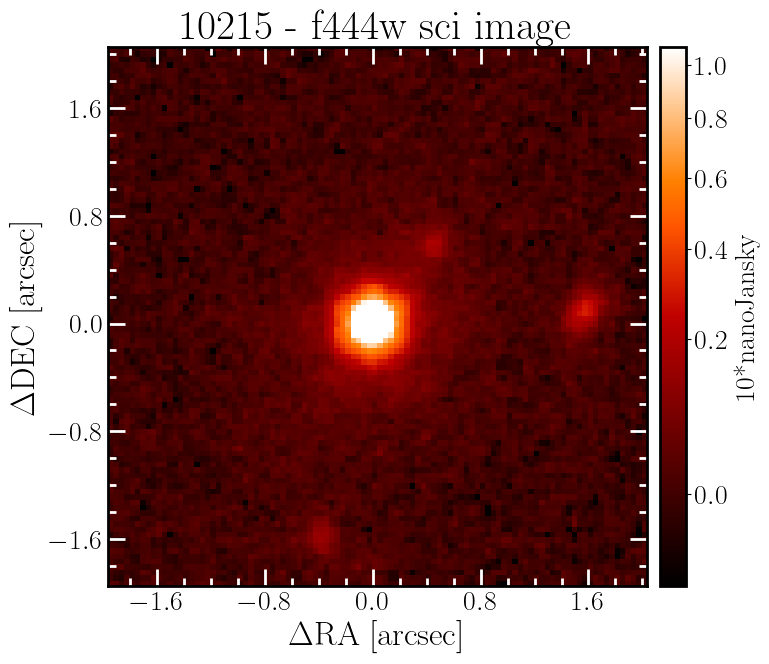

In [125]:
#Make Background Images with Masked Sources 
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
n = 7

Image_ind = Images[n]
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 21
pad_fraction = 0.5
fig, ax = plt.subplots(1, 1, figsize=(10,7))

norm = limits_plot_color(Image_ind, 99.)
plot_1 = ax.imshow(Image_ind, cmap=plt.cm.gist_heat, origin='lower',norm = norm)
divider = make_axes_locatable(ax)
width = axes_size.AxesY(ax, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
cax = divider.append_axes("right", size=width, pad=pad)
cbar = plt.colorbar(plot_1, cax=cax, label='10*nanoJansky')
ticklabs = cbar.ax.get_yticklabels()
cbar.ax.set_yticklabels(ticklabs, fontsize=20)
ticklabs = cbar.ax.get_ylabel()
cbar.ax.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax.set_title(title_name + ' - ' + Filters_ind + ' sci image', size=30) 

ax.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.8 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax.set_yticks(pixHx+med[0])
ax.set_xticks(pixHy+med[1])
ax.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax.tick_params(direction='in',color='white',length=10,width=2,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2,top='True',right='True',which='minor')

ax.set_ylabel('$\Delta$DEC [arcsec]', size=24)
ax.set_xlabel('$\Delta$RA [arcsec]', size=24)
#ax.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
#ax.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))
ax.minorticks_on()
ax.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')

plt.savefig(dir_output + title_name + '_' + Filters_ind + ' sci img' + '.pdf',format='pdf',bbox_inches='tight')

plt.show()
%matplotlib inline

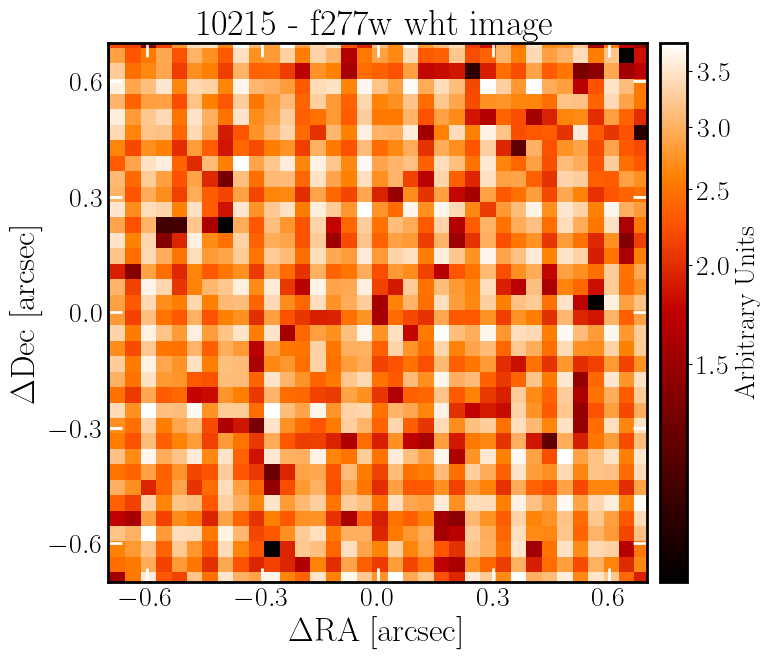

In [21]:
Image_ind_wht = Images_wht[n]*1000
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 20
pad_fraction = 0.5
fig, ax = plt.subplots(1, 1, figsize=(10,7))

norm = limits_plot_color(Image_ind_wht, 99.)
plot_1 = ax.imshow(Image_ind_wht, cmap=plt.cm.gist_heat, origin='lower',norm = norm)
divider = make_axes_locatable(ax)
width = axes_size.AxesY(ax, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
cax = divider.append_axes("right", size=width, pad=pad)
cbar = plt.colorbar(plot_1, cax=cax, label='Arbitrary Units')
ticklabs = cbar.ax.get_yticklabels()
cbar.ax.set_yticklabels(ticklabs, fontsize=20)
ticklabs = cbar.ax.get_ylabel()
cbar.ax.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax.set_title(title_name + ' - ' + Filters_ind + ' wht image', size=26) 

ax.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.3 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax.set_yticks(pixHx+med[0])
ax.set_xticks(pixHy+med[1])
ax.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax.tick_params(direction='in',color='white',length=10,width=2,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2,top='True',right='True',which='minor')

ax.set_ylabel('$\Delta$Dec [arcsec]', size=24)
ax.set_xlabel('$\Delta$RA [arcsec]', size=24)
ax.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
ax.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))

plt.savefig(dir_output + title_name + '_' + Filters_ind + ' wht image' + '.pdf',format='pdf',bbox_inches='tight')

plt.show()

In [22]:
# Radius of the circular aperture 
r_aper = 0.35 # arcsec
r_aper_pix = r_aper/(np.array(CDELT_x))  # pixel

# Inner and outter radius of the background annulus aperture
r_in = 0.85  # arcsec
r_out = 1  # arcsec
r_in_pix = r_in/(np.array(CDELT_x))  # pixel
r_out_pix = r_out/(np.array(CDELT_x))  # pixel 

x_centroid_array = []
y_centroid_array = []
for i in range(len(Filters)):
   
    # Transform the X and Y coordinates in pixels
    x_centroid_temp, y_centroid_temp = w[i].wcs_world2pix(coord_ra, coord_dec, 0)

    # Calculate the centroide of the source in the specific image
    x_centroid, y_centroid = centroid_sources(Images[i], x_centroid_temp, y_centroid_temp, box_size=11, centroid_func=centroid_com)   

    x_centroid_array.append(x_centroid[0])
    y_centroid_array.append(y_centroid[0]) 

#print(x_centroid_array)
#print(y_centroid_array)

print(x_centroid_array)
print(y_centroid_array)

[49.00218401037778, 48.882062532595626, 48.75347199301757, 48.69332347586304, 48.61473130949101, 48.63558187700503, 48.662130061704666, 48.640853447938156]
[48.49859676595547, 48.371196860297935, 48.329596533332854, 48.25145769362426, 48.226569142761605, 48.1446165424245, 48.14005136935944, 48.167372249802895]


In [23]:
bkg_estimator = MedianBackground()
def segm(Image_array, Image_wht_array, Filters, sel_filter, thresh=1.5, var=False, minarea=5, deblend_nthresh=32, deblend_cont=0.01, photutils = True):
	import sep 
	from astropy.stats import sigma_clipped_stats, SigmaClip
	from photutils.segmentation import detect_threshold, detect_sources, deblend_sources
	from photutils.utils import circular_footprint
	from astropy.convolution import convolve
	from photutils.segmentation import make_2dgaussian_kernel

	idx = Filters.index(sel_filter)
	data_img = Image_array[idx]

	if photutils is False: 
		data_img = np.ascontiguousarray(data_img.astype(np.float32))
	else:
		data_img = data_img

	kernel = make_2dgaussian_kernel(3.0, size=5)  # FWHM = 3.0
	convolved_data = convolve(data_img, kernel)
	sigma_clip = SigmaClip(sigma=3.0, maxiters=10)
	threshold = detect_threshold(data_img, nsigma=2.0, sigma_clip=sigma_clip)

	if var is False:
		rows,cols = np.where((np.isnan(data_img)==False) & (np.isinf(data_img)==False))
		err = np.percentile(data_img[rows,cols], 2.5)
	else:
		data_var = Image_wht_array[idx]
		data_var =  np.ascontiguousarray(data_var.astype(np.float32))
		err = 1.0 / np.sqrt(data_var) 


	if photutils is True: 
		segm = detect_sources(convolved_data, threshold, minarea)
		segm_map = deblend_sources(convolved_data, segm,
                               npixels=minarea, nlevels=deblend_nthresh, contrast=deblend_cont,
                               progress_bar=False)

	else: 
		objects, segm_map = sep.extract(data=convolved_data, thresh=thresh, err=err, minarea=minarea, 
									deblend_nthresh=deblend_nthresh, deblend_cont=deblend_cont, 
									segmentation_map=True)

	return segm_map


def mask_region_bgmodel(Image_array, Image_wht_array, Filters, sel_filter, 
                        thresh=1.5, var=True, minarea=5, 
                        deblend_nthresh=32, deblend_cont=0.01, 
                        photutils=True, dilation_pixels=5):

    idx = Filters.index(sel_filter)

    # Generate the segmentation map
    if photutils is True: 
        segm_map = segm(Image_array, Image_wht_array, Filters, sel_filter, 
                        thresh=thresh, var=var, minarea=minarea, 
                        deblend_nthresh=deblend_nthresh, deblend_cont=deblend_cont, 
                        photutils=True)
        # Handle Photutils Segmentation object vs raw array
        if hasattr(segm_map, 'data'):
            segm_map = segm_map.data
    else: 
        segm_map = segm(Image_array, Image_wht_array, Filters, sel_filter, 
                        thresh=thresh, var=var, minarea=minarea, 
                        deblend_nthresh=deblend_nthresh, deblend_cont=deblend_cont, 
                        photutils=False)

    # 1. Create initial boolean mask (True where there are sources)
    mask_region = segm_map > 0

    return mask_region

In [24]:
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel
from photutils.segmentation import detect_threshold, detect_sources, deblend_sources
from photutils.segmentation import SourceCatalog

def ellipse_sma(ell, pa, x_norm, y_norm):
    # Convert inputs to arrays for vectorization
    x_norm, y_norm = np.asarray(x_norm), np.asarray(y_norm)

    # 1. Rotate coordinates to align with the ellipse axes
    # Note: Ensure pa is in radians. 
    # If your PA is from North through East, you might need pa + np.pi/2
    cos_pa = np.cos(pa)
    sin_pa = np.sin(pa)
    
    x_rot = x_norm * cos_pa + y_norm * sin_pa
    y_rot = -x_norm * sin_pa + y_norm * cos_pa 

    # 2. Calculate the Semi-Major Axis (sma)
    # The 'stretch' 1/(1-ell) belongs on the minor axis (y_rot) 
    # to scale it up to the equivalent major axis distance.
    sma = np.sqrt(x_rot**2 + (y_rot / (1.0 - ell))**2)

    return sma

def crop_ellipse_galregion(gal_region0, x_cent, y_cent, ell, pa, rmax):

    dim_y = gal_region0.shape[0]
    dim_x = gal_region0.shape[1]

    x = np.linspace(0, dim_x - 1, dim_x)
    y = np.linspace(0, dim_y - 1, dim_y)
    xx, yy = np.meshgrid(x,y) 
    xx_norm = xx - x_cent 
    yy_norm = yy - y_cent 

    data2D_sma = ellipse_sma(ell, pa, xx_norm, yy_norm)

    rows, cols = np.where((data2D_sma <= rmax) & (gal_region0 == 1))

    gal_region = np.zeros((dim_y, dim_x))
    gal_region[rows, cols] = 1

    return gal_region

def obtain_ellipse(Image_array, Filter_array, sel_filter, x_cent, y_cent):

    idx = Filters.index(sel_filter)
    image_temp = Image_array[idx]
    mask = mask_region_bgmodel(Images, Images_wht, Filters, Filters[i])
    bkg = Background2D(image_temp, (30, 30), filter_size=(3, 3),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)
    bkg_s_img = image_temp - bkg.background
    norm = limits_plot_color(bkg_s_img,99.0)

    # Segmentation 
    threshold = 1.5 * bkg.background_rms
    kernel = make_2dgaussian_kernel(3.0, size=9)  # FWHM = 3.0
    convolved_data = convolve(bkg_s_img, kernel)
    segment_map = detect_sources(convolved_data, threshold, npixels=5)
    segm_deblend = deblend_sources(convolved_data, segment_map, npixels=5, nlevels=32, contrast=0.01, progress_bar=False)
    cat = SourceCatalog(bkg_s_img, segm_deblend, convolved_data=convolved_data, background = bkg.background)

    # Plot the kron aperture 
    #plt.imshow(segm_deblend, origin='lower', cmap=segm_deblend.cmap, interpolation='nearest')
    #cat.plot_kron_apertures(color='white', lw=1.5)
    columns = ['label', 'xcentroid', 'ycentroid', 'ellipticity', 'orientation', "semimajor_sigma", "semiminor_sigma", "kron_radius", "kron_aperture"]
    tbl = cat.to_table(columns = columns)

    # Reference position
    x0, y0 = x_cent, y_cent 

    # Source centroids from catalog
    x = tbl['xcentroid'].value
    y = tbl['ycentroid'].value

    # Euclidean distance in pixel space
    dist = np.sqrt((x - x0)**2 + (y - y0)**2)

    # Index of closest source
    idx = np.argmin(dist)

    # Select that row
    segm_regions = tbl 
    closest_source = tbl[idx]

    # Create gal_region0 - a binary mask 
    gal_label = idx + 1 
    seg_data = segm_deblend.data   # this is a 2D numpy array
    gal_region0 = (seg_data == gal_label).astype(int)
    all_gal_region0 = (seg_data > 0).astype(int)
    not_gal_region0 = all_gal_region0 - gal_region0
    
    return gal_region0, closest_source, segm_deblend, not_gal_region0

def extract_ellipse(closest_source):
    ell = closest_source["ellipticity"]
    pa = closest_source["orientation"].to("radian").value
    major_sigma = closest_source["semimajor_sigma"]
    minor_sigma = closest_source["semiminor_sigma"]
    scale = 2.5 * closest_source["kron_radius"]
    a = major_sigma * scale 
    b = minor_sigma * scale
    kron_aperture = closest_source["kron_aperture"]
    positions = kron_aperture.positions

    return ell, pa, a, b, positions

In [25]:
gal_region0, ellipse, segm_deblend, not_gal_region0 = obtain_ellipse(Images, Filters, 'f444w', x_centroid_array[7], y_centroid_array[7])
print(gal_region0.shape)

ell, pa, rmax, b, positions = extract_ellipse(ellipse) 
print(pa)
x_centroid_new = positions[0]
y_centroid_new = positions[1]

(100, 100)
0.7887238464189208


0.04808924248655577 0.7887238464189208 17.16899390083322 pix2 16.34334998988586 pix2
[48.56961877 47.88172259]
17.16899390083322


Text(0.5, 1.0, 'Segmentation Image - Galaxy ID: 10215')

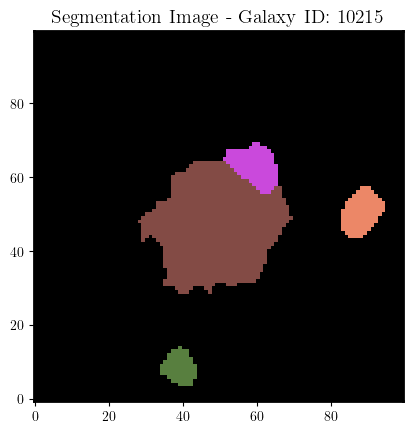

In [26]:
from photutils.aperture import EllipticalAperture

# Extract the elliptical aperture 
# Extract the elliptical aperture 
ell, pa, a, b, positions = extract_ellipse(ellipse)
print(ell, pa, a, b)
print(positions)
rmax = a.value 
print(rmax)

# Test the sma function 
crop_ellipse = crop_ellipse_galregion(gal_region0, positions[0], positions[1], ell, pa, rmax)
crop_not_ellipse = crop_ellipse_galregion(not_gal_region0, positions[0], positions[1], ell, pa, rmax)
aper = EllipticalAperture(positions, a.value, b.value, theta=pa)
#aper.plot(color = 'yellow')
plt.imshow(segm_deblend, origin='lower', cmap=segm_deblend.cmap)
plt.title(f'Segmentation Image - Galaxy ID: {title_name}', size=14) 

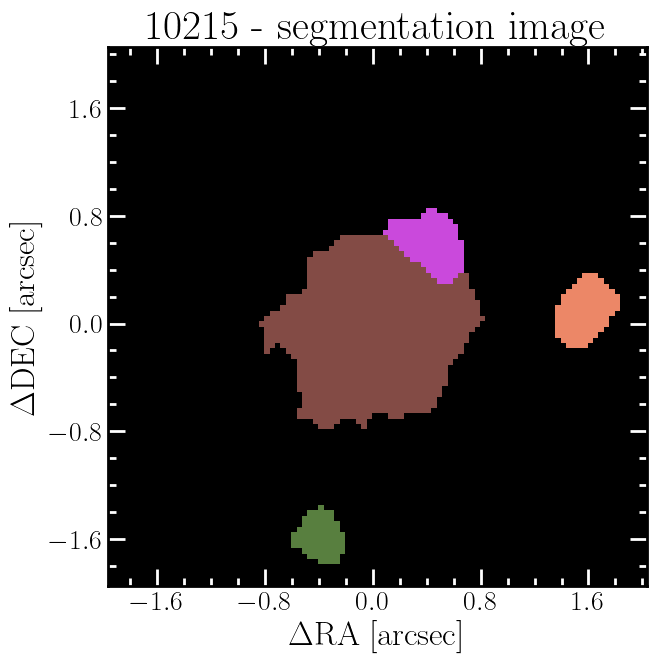

In [118]:
#Make Background Images with Masked Sources 
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
n = 4

Image_ind = segm_deblend
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 21
pad_fraction = 0.5
fig, ax = plt.subplots(1, 1, figsize=(10,7))

#norm = limits_plot_color(Image_ind, 99.)
plot_1 = ax.imshow(Image_ind, cmap=segm_deblend.cmap, origin='lower')
divider = make_axes_locatable(ax)
width = axes_size.AxesY(ax, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
#cax = divider.append_axes("right", size=width, pad=pad)
#cbar = plt.colorbar(plot_1, cax=cax, label='10nJy')
ticklabs = cbar.ax.get_yticklabels()
#cbar.ax.set_yticklabels(ticklabs, fontsize=20)
ticklabs = cbar.ax.get_ylabel()
cbar.ax.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax.set_title(title_name + ' - ' + ' segmentation image', size=30) 

ax.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.8 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax.set_yticks(pixHx+med[0])
ax.set_xticks(pixHy+med[1])
ax.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax.tick_params(direction='in',color='white',length=10,width=2,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2,top='True',right='True',which='minor')

ax.set_ylabel('$\Delta$DEC [arcsec]', size=24)
ax.set_xlabel('$\Delta$RA [arcsec]', size=24)
#ax.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
#ax.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))
ax.minorticks_on()
ax.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')

plt.show()
%matplotlib inline

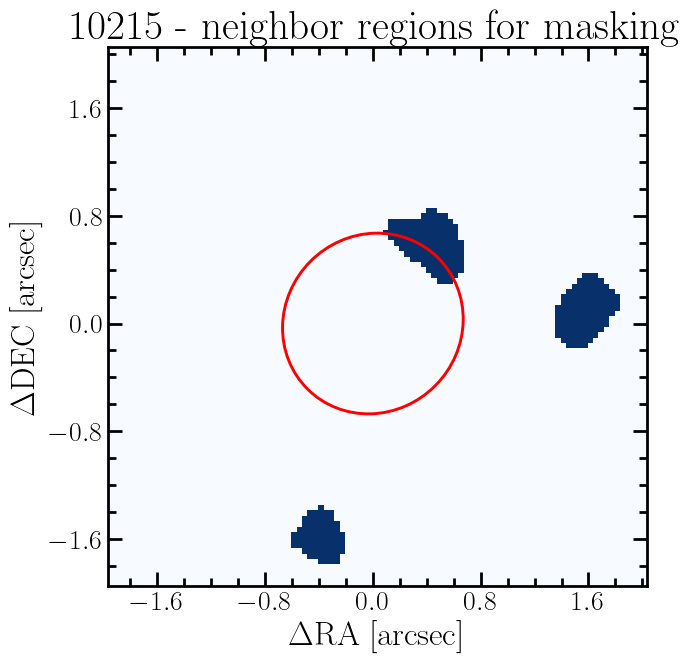

In [122]:
#Make Background Images with Masked Sources 
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
n = 4

Image_ind = not_gal_region0
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 21
pad_fraction = 0.5
fig1, ax1 = plt.subplots(1, 1, figsize=(10,7))

#norm = limits_plot_color(Image_ind, 99.)
plot_2 = ax1.imshow(Image_ind, cmap='Blues', origin='lower')
divider = make_axes_locatable(ax1)
width = axes_size.AxesY(ax1, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
#cax1 = divider.append_ax1es("right", size=width, pad=pad)
#cbar = plt.colorbar(plot_1, cax1=cax1, label='10nJy')
#ticklabs = cbar.ax.get_yticklabels()
#cbar.ax1.set_yticklabels(ticklabs, fontsize=20)
#ticklabs = cbar.ax.get_ylabel()
#cbar.ax1.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax1.set_title(title_name + ' - ' + ' neighbor regions for masking', size=30) 

ax1.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.8 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax1.set_yticks(pixHx+med[0])
ax1.set_xticks(pixHy+med[1])
ax1.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax1.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax1.minorticks_on()
ax1.tick_params(direction='in',color='black',length=10,width=2,top='True',right='True',which='major')
ax1.tick_params(direction='in',color='black',length=6,width=2,top='True',right='True',which='minor')

ax1.set_ylabel('$\Delta$DEC [arcsec]', size=24)
ax1.set_xlabel('$\Delta$RA [arcsec]', size=24)
#ax1.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
#ax1.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))


aper.plot(color = 'red', lw = 2.1)

plt.show()

<photutils.segmentation.core.SegmentationImage>
shape: (100, 100)
nlabels: 4
labels: [1 2 3 4]


Text(0.5, 1.0, 'Galaxy Region Before Cropping - Galaxy ID: 10215')

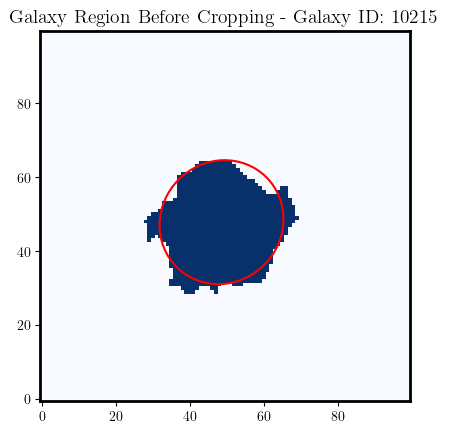

In [27]:
print(segm_deblend)
plt.imshow(gal_region0, origin = 'lower', cmap = 'Blues')
aper.plot(color = 'red', lw = 1.5)
plt.title(f'Galaxy Region Before Cropping - Galaxy ID: {title_name}', size=14) 

<photutils.segmentation.core.SegmentationImage>
shape: (100, 100)
nlabels: 4
labels: [1 2 3 4]


Text(0.5, 1.0, 'Neighboring Regions - Galaxy ID: 10215')

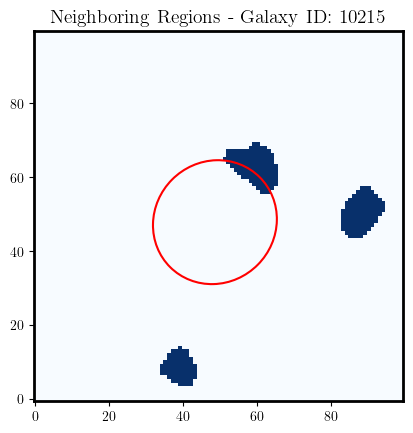

In [28]:
print(segm_deblend)
plt.imshow(segm_deblend, origin='lower', cmap=segm_deblend.cmap, interpolation='nearest')
plt.imshow(not_gal_region0, origin = 'lower', cmap = 'Blues')
aper.plot(color = 'red', lw = 1.5)
plt.title(f'Neighboring Regions - Galaxy ID: {title_name}', size=14) 

Text(0.5, 1.0, 'Galaxy Region After Cropping - Galaxy ID: 10215')

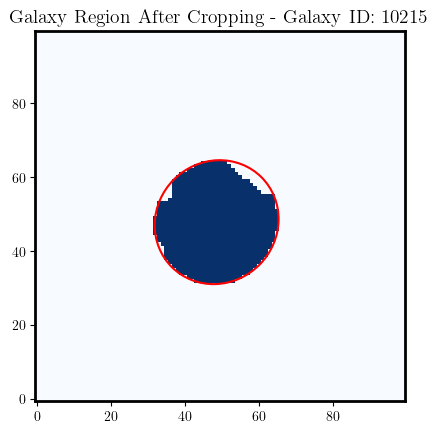

In [29]:
aper.plot(color = 'red', lw = 1.5)
plt.imshow(crop_ellipse, origin='lower', cmap = 'Blues')
plt.title(f'Galaxy Region After Cropping - Galaxy ID: {title_name}', size=14) 

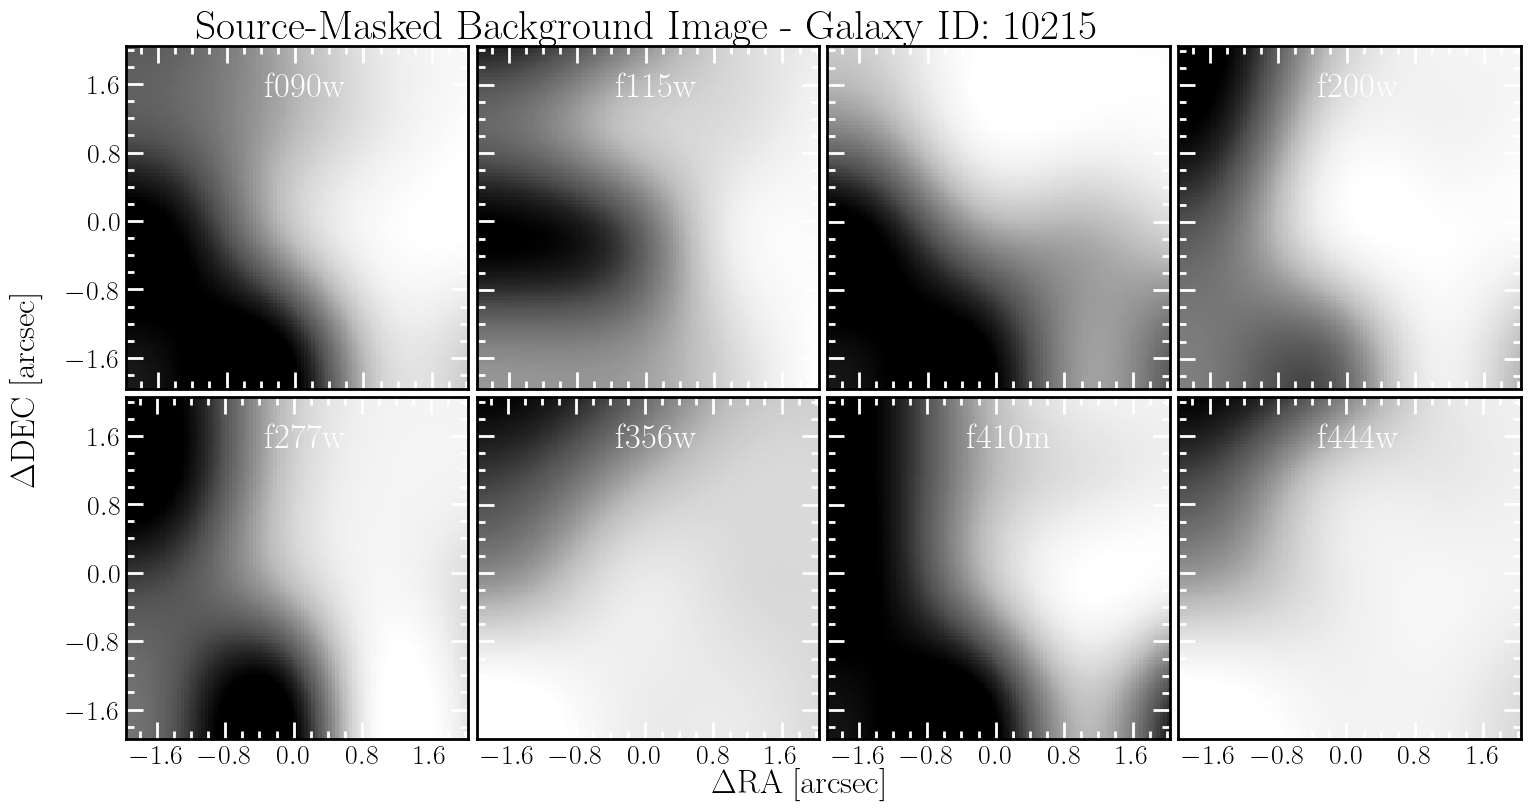

In [33]:
# Background Images 

fig = plt.figure(figsize=(18, 9))
grid = plt.GridSpec(2, 4, hspace=0.025, wspace=0.025)
bkg_estimator = MedianBackground()
bkg_array = [] 

for i in range(len(Filters)):
     
    image_temp = Images[i]
    wcs_temp = w[i]
    CDELT_temp = CDELT_x[i]
    if i > -1:
        mask = mask_region_bgmodel(Images, Images_wht, Filters, Filters[i], photutils = True)

    # Make Background Images 
    if i > -1:
        bkg = Background2D(image_temp, (30, 30), filter_size=(3, 3),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator, mask = mask)
        
    else:
        bkg = Background2D(image_temp, (30, 30), filter_size=(3, 3),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)
       
    
    if i < 3.5:
        s = i
        r = 0
    if (i > 3.5) & (i < 7.5):
        s = i - 4
        r = 1
    if i > 7.5:
        s = i - 6
        r = 2 
        
    axs_temp = fig.add_subplot(grid[r:r+1,s:s+1])
    
    #norm = limits_plot_color(image_temp,99.0)
    axs_temp.imshow(bkg.background, origin='lower', cmap='Greys_r', interpolation='nearest')
    bkg_array.append(bkg.background)
       
    axs_temp.set_box_aspect(1)
    med=[y_centroid_array[i],x_centroid_array[i]]  
    jump=0.8 #arcsec
    jumpix=jump/(CDELT_temp)
    pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
    pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
    axs_temp.set_yticks(pixHx+med[0])
    axs_temp.set_xticks(pixHy+med[1])
    axs_temp.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_temp)], fontsize=20)
    axs_temp.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_temp)], fontsize=20)

    # Tick_params and labels
    if s == 0:
        if r == 0:
            axs_temp.tick_params(labelbottom=False, labelsize=20)         
    if r == 1:
        if s > 0.1:
            axs_temp.tick_params(labelleft=False, labelsize=20)
    if r < 1:
        if s > 0.1:
            axs_temp.tick_params(labelbottom=False, labelleft=False, labelsize=20)   
  
    axs_temp.minorticks_on()
    axs_temp.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
    axs_temp.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')

    #Filter names
    axs_temp.text(50*0.8, 50*1.7, Filters[i],color='white', size=25)


    axs_temp.tick_params(labelsize=20)
    #axs[r,s].set_ylabel('Dec', size=20)
    #axs[r,s].set_xlabel('RA', size=20)
    #axs_temp.set_xlim(x_centroid_array[i]-box_size/(CDELT_temp), x_centroid_array[i]+box_size/(CDELT_temp))
    #axs_temp.set_ylim(y_centroid_array[i]-box_size/(CDELT_temp), y_centroid_array[i]+box_size/(CDELT_temp))

fig.axes[0].set_ylabel('$\Delta$DEC [arcsec]', fontsize=24, va='center', ha='center')
fig.axes[0].yaxis.set_label_coords(0.07, 0.5, transform=fig.transFigure)
fig.axes[0].autoscale_view()

fig.axes[0].set_xlabel('$\Delta$RA [arcsec]', fontsize=24, va='center', ha='center')
fig.axes[0].xaxis.set_label_coords(0.5, 0.06, transform=fig.transFigure)
fig.axes[0].autoscale_view()
title_name = str(Name.item())
fig.axes[1].set_title(f'                           Source-Masked Background Image - Galaxy ID: {title_name}', size=30) 

plt.savefig(dir_output + title_name + '_ALL_BKG_IMAGES.pdf',format='pdf',bbox_inches='tight')
plt.show()

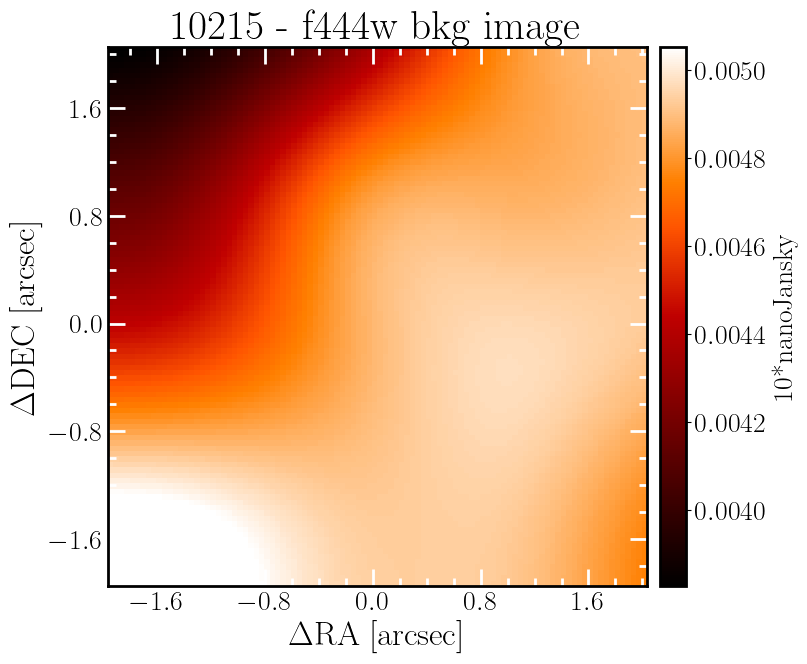

In [126]:
#Make Background Images with Masked Sources 
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
n = 7

Image_ind = bkg_array[n]
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 21
pad_fraction = 0.5
fig, ax = plt.subplots(1, 1, figsize=(10,7))

norm = limits_plot_color(Image_ind, 99.)
plot_1 = ax.imshow(Image_ind, cmap=plt.cm.gist_heat, origin='lower', interpolation='nearest')
divider = make_axes_locatable(ax)
width = axes_size.AxesY(ax, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
cax = divider.append_axes("right", size=width, pad=pad)
cbar = plt.colorbar(plot_1, cax=cax, label='10*nanoJansky')
ticklabs = cbar.ax.get_yticklabels()
cbar.ax.set_yticklabels(ticklabs, fontsize=20)
ticklabs = cbar.ax.get_ylabel()
cbar.ax.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax.set_title(title_name + ' - ' + Filters_ind + ' bkg image', size=30) 

ax.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.8 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax.set_yticks(pixHx+med[0])
ax.set_xticks(pixHy+med[1])
ax.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax.tick_params(direction='in',color='white',length=10,width=2,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2,top='True',right='True',which='minor')

ax.set_ylabel('$\Delta$DEC [arcsec]', size=24)
ax.set_xlabel('$\Delta$RA [arcsec]', size=24)
#ax.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
#ax.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))
ax.minorticks_on()
ax.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')

plt.savefig(dir_output + title_name + '_' + Filters_ind + ' bkg img' + '.pdf',format='pdf',bbox_inches='tight')

plt.show()
%matplotlib inline

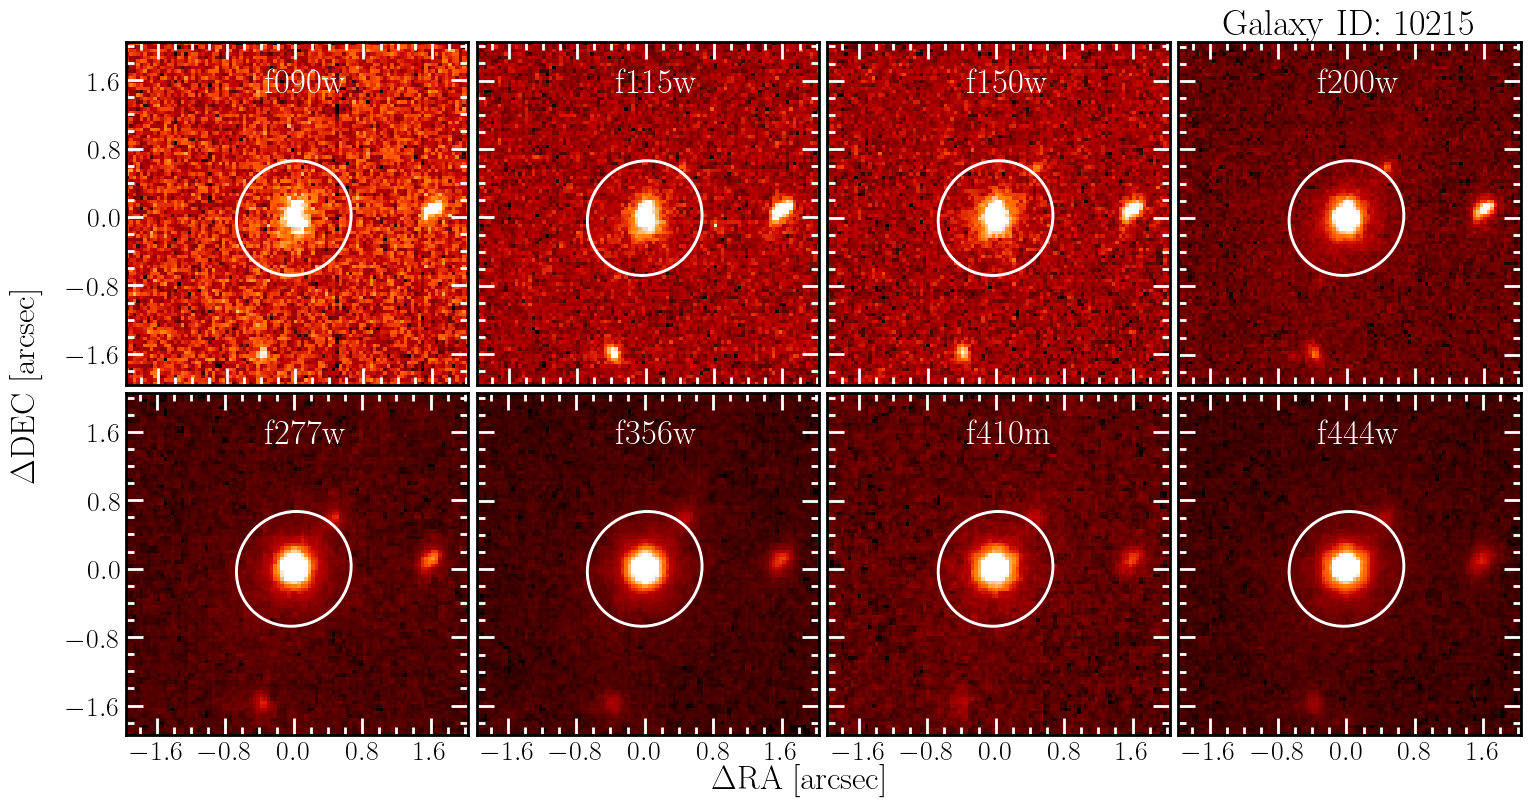

In [70]:
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

fig = plt.figure(figsize=(18, 9))
grid = plt.GridSpec(2, 4, hspace=0.025, wspace=0.025)

Filters_real = ['f115w', 'f150w', 'f277w', 'f444w']
mask_0 = (not_gal_region0) == 1
Images_subtracted = [] 

for i in range(len(Filters)):
     
    image_temp = Images[i] 
    wcs_temp = w[i]
    CDELT_temp = CDELT_x[i]

    if i > -1:
        mask = mask_region_bgmodel(Images, Images_wht, Filters, Filters[i], photutils = True)

    # Make Background Images 
    if i > -1:
        bkg = Background2D(image_temp, (30, 30), filter_size=(3, 3),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator, mask = mask)
    else:
        bkg = Background2D(image_temp, (30, 30), filter_size=(3, 3),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)
    
    # Subtracted Background
    image_subtracted = image_temp - bkg.background
    
    #Aperture sizes
    if i < 3.5:
        s = i
        r = 0
    if (i > 3.5) & (i < 7.5):
        s = i - 4
        r = 1
    if i > 7.5:
        s = i - 6
        r = 2 
        
    axs_temp = fig.add_subplot(grid[r:r+1,s:s+1])
    
    norm = limits_plot_color(image_subtracted,99.0)
    axs_temp.imshow(image_subtracted, cmap=plt.cm.gist_heat, origin='lower', norm = norm)
    Images_subtracted.append(image_subtracted)

    axs_temp.set_box_aspect(1)
    med=[y_centroid_array[i],x_centroid_array[i]]  
    jump=0.8 #arcsec
    jumpix=jump/(CDELT_temp)
    pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
    pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
    axs_temp.set_yticks(pixHx+med[0])
    axs_temp.set_xticks(pixHy+med[1])
    axs_temp.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_temp)], fontsize=20)
    axs_temp.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_temp)], fontsize=20)

    # Tick_params and labels
    if s == 0:
        if r == 0:
            axs_temp.tick_params(labelbottom=False, labelsize=20)         
    if r == 1:
        if s > 0.1:
            axs_temp.tick_params(labelleft=False, labelsize=20)
    if r < 1:
        if s > 0.1:
            axs_temp.tick_params(labelbottom=False, labelleft=False, labelsize=20)   
  
    axs_temp.minorticks_on()
    axs_temp.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
    axs_temp.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')

    #Filter names
    axs_temp.text(50*0.8, 50*1.7, Filters[i],color='white', size=25)

    #Aperture used
    #a_aper = r_aper/(CDELT_temp)
    #b_aper = r_aper/(CDELT_temp)
    aper = EllipticalAperture([x_centroid_array[7], y_centroid_array[7]], a.value, b.value, theta=pa)
    aper.plot(color = 'white', lw = 2.1)
    #ellipse = Ellipse((x_centroid_array[i], y_centroid_array[i]), a_aper*2., b_aper*2., angle=0, fill=False, linewidth=2., linestyle='dashed', color='white')
    #axs_temp.add_patch(ellipse)


    axs_temp.tick_params(labelsize=20)
    #axs[r,s].set_ylabel('Dec', size=20)
    #axs[r,s].set_xlabel('RA', size=20)
    #axs_temp.set_xlim(x_centroid_array[i]-box_size/(CDELT_temp), x_centroid_array[i]+box_size/(CDELT_temp))
    #axs_temp.set_ylim(y_centroid_array[i]-box_size/(CDELT_temp), y_centroid_array[i]+box_size/(CDELT_temp))

fig.axes[0].set_ylabel('$\Delta$DEC [arcsec]', fontsize=24, va='center', ha='center')
fig.axes[0].yaxis.set_label_coords(0.07, 0.5, transform=fig.transFigure)
fig.axes[0].autoscale_view()

fig.axes[0].set_xlabel('$\Delta$RA [arcsec]', fontsize=24, va='center', ha='center' )
fig.axes[0].xaxis.set_label_coords(0.5, 0.06, transform=fig.transFigure)
fig.axes[0].autoscale_view()
title_name = str(Name.item())
fig.axes[3].set_title(f'Galaxy ID: {title_name}', size=26) 

plt.savefig(dir_output + title_name + '_ALL_SCI_IMAGES.pdf',format='pdf',bbox_inches='tight')
plt.show()

0.04808924248655577 0.7887238464189208 17.16899390083322 pix2 16.34334998988586 pix2
[48.56961877 47.88172259]
17.16899390083322


Text(0.5, 1.0, 'Segmentation Image - Galaxy ID: 10215')

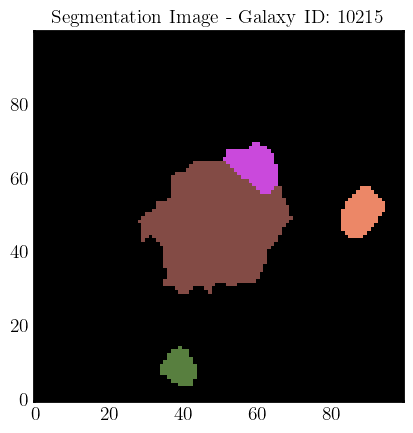

In [1301]:
from photutils.aperture import EllipticalAperture

# Extract the elliptical aperture 
# Extract the elliptical aperture 
ell, pa, a, b, positions = extract_ellipse(ellipse)
print(ell, pa, a, b)
print(positions)
rmax = a.value 
print(rmax)

# Test the sma function 
crop_ellipse = crop_ellipse_galregion(gal_region0, positions[0], positions[1], ell, pa, rmax)
crop_not_ellipse = crop_ellipse_galregion(not_gal_region0, positions[0], positions[1], ell, pa, rmax)
aper = EllipticalAperture(positions, a.value, b.value, theta=pa)
#aper.plot(color = 'yellow')
plt.imshow(segm_deblend, origin='lower', cmap=segm_deblend.cmap)
plt.title(f'Segmentation Image - Galaxy ID: {title_name}', size=14) 

Text(0.5, 1.0, 'Galaxy ID: 10215')

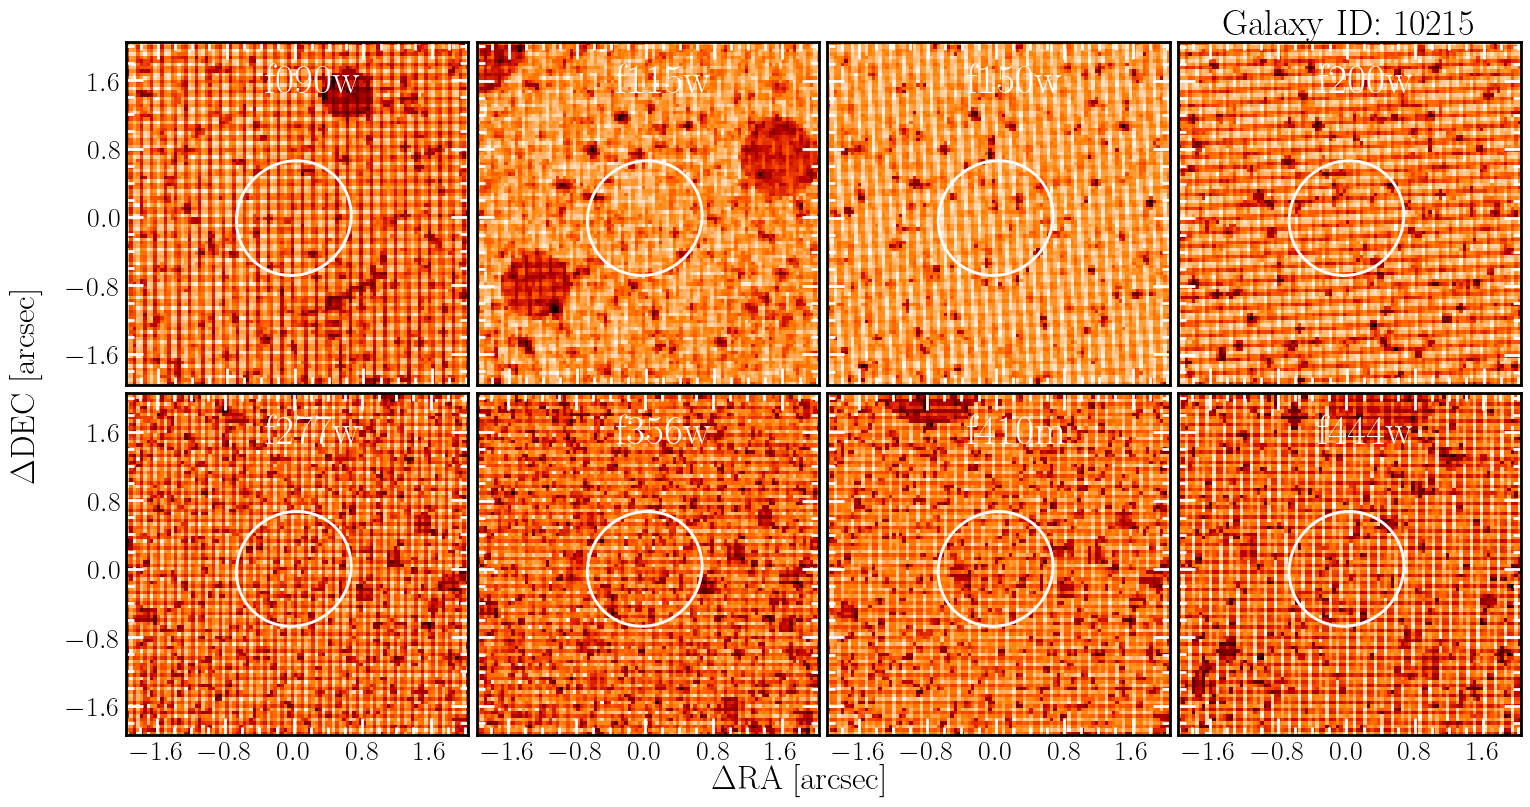

In [ ]:
fig = plt.figure(figsize=(18, 9))
grid = plt.GridSpec(2, 4, hspace=0.025, wspace=0.025)
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

for i in range(len(Filters)):
     
    image_temp_wht = Images_wht[i]*1000 
    wcs_temp = w[i]
    CDELT_temp = CDELT_x[i]
    
    #Aperture sizes
    if i < 3.5:
        s = i
        r = 0
    if (i > 3.5) & (i < 7.5):
        s = i - 4
        r = 1
    if i > 7.5:
        s = i - 6
        r = 2 
        
    axs_temp = fig.add_subplot(grid[r:r+1,s:s+1])
    
    norm = limits_plot_color(image_temp_wht,99.0)
    axs_temp.imshow(image_temp_wht, cmap=plt.cm.gist_heat, origin='lower', interpolation='nearest')
       

    axs_temp.set_box_aspect(1)
    med=[y_centroid_array[i],x_centroid_array[i]]  
    jump=0.8 #arcsec
    jumpix=jump/(CDELT_temp)
    pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
    pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
    axs_temp.set_yticks(pixHx+med[0])
    axs_temp.set_xticks(pixHy+med[1])
    axs_temp.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_temp)], fontsize=20)
    axs_temp.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_temp)], fontsize=20)

    # Tick_params and labels
    if s == 0:
        if r == 0:
            axs_temp.tick_params(labelbottom=False, labelsize=20)         
    if r == 1:
        if s > 0.1:
            axs_temp.tick_params(labelleft=False, labelsize=20)
    if r < 1:
        if s > 0.1:
            axs_temp.tick_params(labelbottom=False, labelleft=False, labelsize=20)   
  
    axs_temp.minorticks_on()
    axs_temp.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
    axs_temp.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')

    #Filter names
    axs_temp.text(50*0.8, 50*1.7, Filters[i],color='white', size=30)

    #Aperture used
    #a_aper = r_aper/(CDELT_temp)
    #b_aper = r_aper/(CDELT_temp)
    #ellipse = Ellipse((x_centroid_array[i], y_centroid_array[i]), a_aper*2., b_aper*2., angle=0, fill=False, linewidth=2., linestyle='dashed', color='white')
    #axs_temp.add_patch(ellipse)
    aper = EllipticalAperture([x_centroid_array[7], y_centroid_array[7]], a.value, b.value, theta=pa)
    aper.plot(color = 'white', lw = 2.1)


    axs_temp.tick_params(labelsize=20)
    #axs[r,s].set_ylabel('Dec', size=20)
    #axs[r,s].set_xlabel('RA', size=20)
    #axs_temp.set_xlim(x_centroid_array[i]-box_size/(CDELT_temp), x_centroid_array[i]+box_size/(CDELT_temp))
    #axs_temp.set_ylim(y_centroid_array[i]-box_size/(CDELT_temp), y_centroid_array[i]+box_size/(CDELT_temp))

fig.axes[0].set_ylabel('$\Delta$DEC [arcsec]', fontsize=24, va='center', ha='center')
fig.axes[0].yaxis.set_label_coords(0.07, 0.5, transform=fig.transFigure)
fig.axes[0].autoscale_view()

fig.axes[0].set_xlabel('$\Delta$RA [arcsec]', fontsize=24, va='center', ha='center')
fig.axes[0].xaxis.set_label_coords(0.5, 0.06, transform=fig.transFigure)
fig.axes[0].autoscale_view()
title_name = str(Name.item())
fig.axes[3].set_title(f'Galaxy ID: {title_name}', size=26) 

#plt.savefig(dir_output + title_name + '_ALL_WHT_IMAGES.pdf',format='pdf',bbox_inches='tight')

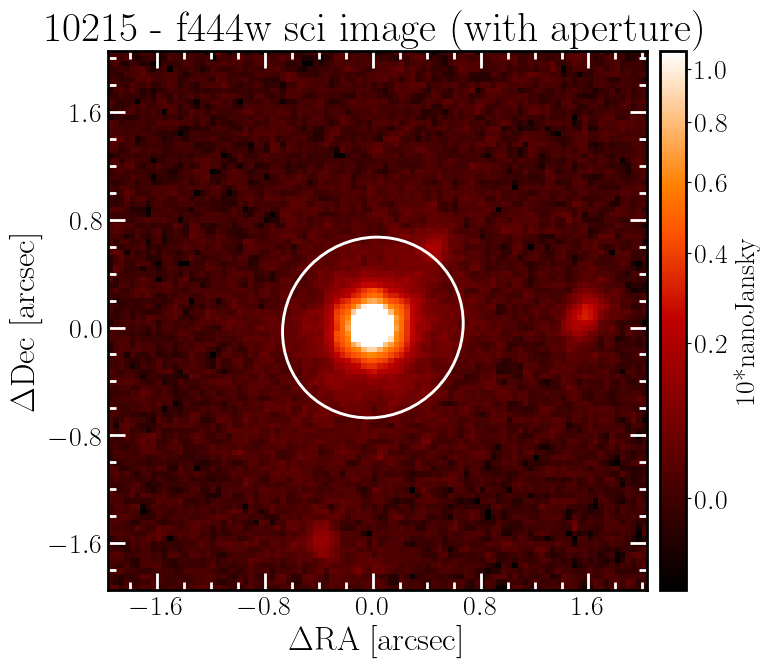

In [123]:
#Make Background Images with Masked Sources 
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
n = 7

Image_ind = Images[n]
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 21
pad_fraction = 0.5
fig, ax = plt.subplots(1, 1, figsize=(10,7))

norm = limits_plot_color(Image_ind, 99.)
plot_1 = ax.imshow(Image_ind, cmap=plt.cm.gist_heat, origin='lower', norm = norm)
divider = make_axes_locatable(ax)
width = axes_size.AxesY(ax, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
cax = divider.append_axes("right", size=width, pad=pad)
cbar = plt.colorbar(plot_1, cax=cax, label='10*nanoJansky')
ticklabs = cbar.ax.get_yticklabels()
cbar.ax.set_yticklabels(ticklabs, fontsize=20)
ticklabs = cbar.ax.get_ylabel()
cbar.ax.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax.set_title(title_name + ' - ' + Filters_ind + ' sci image (with aperture)', size=30) 

ax.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.8 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax.set_yticks(pixHx+med[0])
ax.set_xticks(pixHy+med[1])
ax.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax.tick_params(direction='in',color='white',length=10,width=2,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2,top='True',right='True',which='minor')

ax.set_ylabel('$\Delta$Dec [arcsec]', size=24)
ax.set_xlabel('$\Delta$RA [arcsec]', size=24)
#ax.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
#ax.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))
ax.minorticks_on()
ax.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')
aper.plot(ax, color = 'white', lw = 2.1)


plt.show()
%matplotlib inline

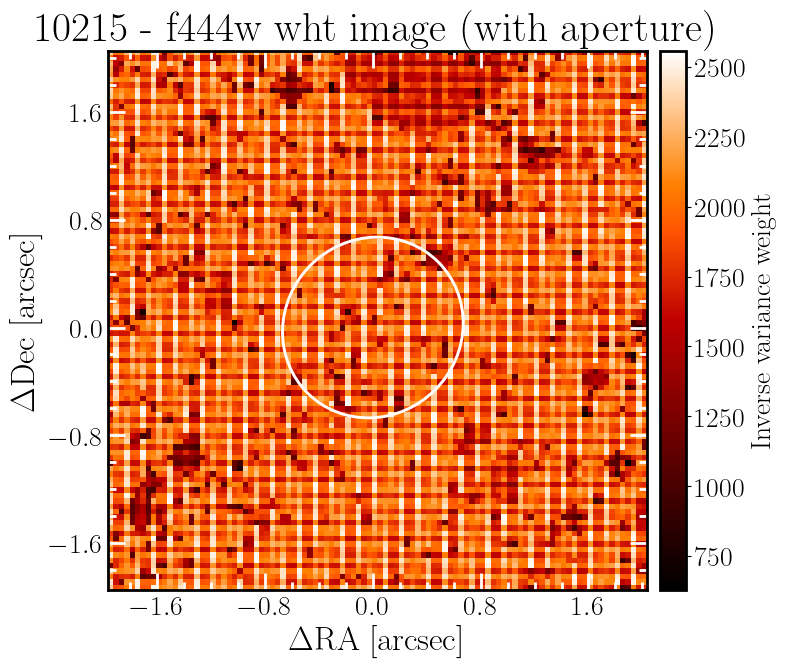

In [124]:
#Make Background Images with Masked Sources 
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
n = 7

Image_ind = Images_wht[n]
Filters_ind = Filters[n]
CDELT_x_ind = CDELT_x[n]

aspect = 21
pad_fraction = 0.5
fig, ax = plt.subplots(1, 1, figsize=(10,7))

norm = limits_plot_color(Image_ind, 99.)
plot_1 = ax.imshow(Image_ind, cmap=plt.cm.gist_heat, origin='lower', interpolation='nearest')
divider = make_axes_locatable(ax)
width = axes_size.AxesY(ax, aspect=1./aspect)
pad = axes_size.Fraction(pad_fraction, width)
cax = divider.append_axes("right", size=width, pad=pad)
cbar = plt.colorbar(plot_1, cax=cax, label='Inverse variance weight')
ticklabs = cbar.ax.get_yticklabels()
cbar.ax.set_yticklabels(ticklabs, fontsize=20)
ticklabs = cbar.ax.get_ylabel()
cbar.ax.set_ylabel(ticklabs, fontsize=20)

title_name = str(Name.item())
ax.set_title(title_name + ' - ' + Filters_ind + ' wht image (with aperture)', size=30) 

ax.set_box_aspect(1)
med=[y_centroid,x_centroid]  
jump=0.8 #arcsec
jumpix=jump/(CDELT_x_ind)
pixHx=np.arange(-med[0]+med[0]%jumpix,med[0],jumpix)
pixHy=np.arange(-med[1]+med[1]%jumpix,med[1],jumpix)
ax.set_yticks(pixHx+med[0])
ax.set_xticks(pixHy+med[1])
ax.set_yticklabels(["$%.1f$"%f for f in pixHx*(CDELT_x_ind)], fontsize=20)
ax.set_xticklabels(["$%.1f$"%f for f in pixHy*(CDELT_x_ind)], fontsize=20)
ax.tick_params(direction='in',color='white',length=10,width=2,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2,top='True',right='True',which='minor')

ax.set_ylabel('$\Delta$Dec [arcsec]', size=24)
ax.set_xlabel('$\Delta$RA [arcsec]', size=24)
#ax.set_ylim(y_centroid-box_size/(CDELT_x_ind),y_centroid+box_size/(CDELT_x_ind))
#ax.set_xlim(x_centroid-box_size/(CDELT_x_ind),x_centroid+box_size/(CDELT_x_ind))
ax.minorticks_on()
ax.tick_params(direction='in',color='white',length=12,width=2.,top='True',right='True',which='major')
ax.tick_params(direction='in',color='white',length=6,width=2.,top='True',right='True',which='minor')
aper.plot(ax, color = 'white', lw = 2.1)


plt.show()
%matplotlib inline

In [1303]:
Flux_array = []
Area_array = []
for i in range(len(Filters)):  

    #Photometry of the source
    Flux_total = aperture_photometry(Images_subtracted[i], aper, method='exact', mask = mask_0)         # 10 * nJy  
    Area_total = aperture_photometry(Images_subtracted[i]*0. + 1., aper, method='exact') # pixels
    Flux_array.append(Flux_total['aperture_sum'][0])
    Area_array.append(Area_total['aperture_sum'][0])

print(Flux_array)
print(Area_array)

[21.00476782397098, 25.756017897275257, 56.772817890457276, 124.99392850286385, 170.18161109301286, 200.39896816367474, 232.47166180351718, 247.7731371267387]
[881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976]


In [1304]:
# Calculating the flux error from the source region using WHT images 
Weight_source_array = []
Area_wht_array = []
Variance_src_array = []
for i in range(len(Filters)):  
    var_clean = Images_var[i].copy()
    # Replace inf with 0
    var_clean[np.isinf(var_clean)] = 0.0
    # Build a mask that excludes inf pixels
    mask_inf = np.isinf(Images_var[i])
    # Combine masks
    combined_mask = mask_0 | mask_inf
    
    #Photometry of the source
    Variance_src_total = aperture_photometry(Images_var[i], aper, method='exact', mask = combined_mask)         # 10 * nJy  
    Area_wht_total = aperture_photometry(Images_wht[i]*0. + 1., aper, method='exact') # pixels
    Variance_src_array.append(Variance_src_total['aperture_sum'][0])
    Area_wht_array.append(Area_wht_total['aperture_sum'][0])

print(Variance_src_array)
print(Area_wht_array)

[0.627599378460508, 0.23374667851360964, 0.6998870608962793, 0.41867536810757333, 0.32972075875738155, 0.22426228644113372, 1.1805101340247868, 0.4394015490664297]
[881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976, 881.5273683755976]


544
[0.0006603203946724534, 0.004549125442281365, 0.0075006065890192986, 0.013242801185697317, 0.011192799545824528, 0.012088360730558634, 0.013497835956513882, 0.01875379215925932]
[0.022458022200474128, 0.014345902171792607, 0.02531078099847481, 0.01900865335192571, 0.014369106684399004, 0.013080899713480082, 0.02524107449003273, 0.015090848243721523]


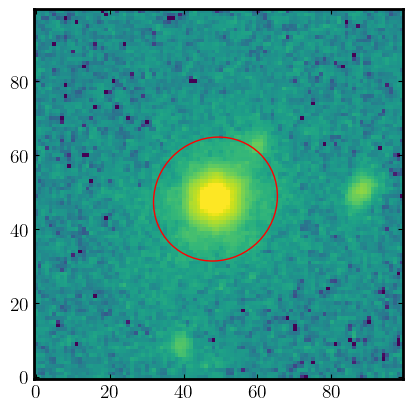

In [1305]:

Median_back_array = []
Std_back_array = []
for i in range(len(Filters)):  
    
    # Define Annulus aperture
    aper_annulus_temp = CircularAnnulus((x_centroid_array[i], y_centroid_array[i]), r_in_pix[i], r_out_pix[i])
    #Background photometry
    annulus_masks = aper_annulus_temp.to_mask(method='center')
    annulus_data = annulus_masks.multiply(Images[i])
    norm = limits_plot_color(annulus_data,99.99)
    annulus_data[annulus_data == 0] = np.nan
    mask = annulus_masks.data
    annulus_data_1d = annulus_data[mask > 0]

    #Plot annulus to check
#    fig, ax = plt.subplots(1, 1, figsize=(10,7))
#    ax.imshow(annulus_data)    
    
    # Median and standard desviation of the background with sigma clipping
    median = np.nanmedian(annulus_data_1d)
    std = np.std(annulus_data_1d)
    
    #Save the results in an array
    Median_back_array.append(median)
    Std_back_array.append(std)

print(np.sum(np.isfinite(annulus_data_1d)))
print(Median_back_array)
print(Std_back_array)


#Plot the background annulus 
#Plot the background annulus 
from astropy.visualization import simple_norm

norm = simple_norm(Images[i], 'log', percent=99.)
plt.imshow(Images[i], norm=norm, origin='lower', cmap='viridis')
#plt.imshow(Images[i], origin='lower', cmap='gray', vmin=norm.vmin, vmax=norm.vmax)
#aper_annulus_temp.plot(color='red')
aper.plot(color='red')
plt.show()

In [1306]:
Median_back_array_wht = []
Std_back_array_wht = []
for i in range(len(Filters)):  
    
    # Define Annulus aperture
    aper_annulus_temp = CircularAnnulus((x_centroid_array[i], y_centroid_array[i]), r_in_pix[i], r_out_pix[i])

    #Background photometry
    annulus_masks = aper_annulus_temp.to_mask(method='center')
    annulus_data = annulus_masks.multiply(Images[i])
    norm = limits_plot_color(annulus_data,99.99)
    annulus_data[annulus_data == 0] = np.nan
    mask = annulus_masks.data
    annulus_data_1d = annulus_data[mask > 0]

    #Plot annulus to check
#    fig, ax = plt.subplots(1, 1, figsize=(10,7))
#    ax.imshow(annulus_data)    
    
    # Median and standard desviation of the background with sigma clipping
    median = np.nanmedian(annulus_data_1d)
    std = np.std(annulus_data_1d)
    
    #Save the results in an array
    Median_back_array_wht.append(median)
    Std_back_array_wht.append(std)

print(np.sum(np.isfinite(annulus_data_1d)))
print(Median_back_array_wht)
print(Std_back_array_wht)

544
[0.0006603203946724534, 0.004549125442281365, 0.0075006065890192986, 0.013242801185697317, 0.011192799545824528, 0.012088360730558634, 0.013497835956513882, 0.01875379215925932]
[0.022458022200474128, 0.014345902171792607, 0.02531078099847481, 0.01900865335192571, 0.014369106684399004, 0.013080899713480082, 0.02524107449003273, 0.015090848243721523]


## Encircled Energy

In [1307]:
file_path = '/Users/quocanh1306/Downloads/PSF_Ceers/'

ee_df_list = ['ee_new_df_f090w.csv', 'ee_df_f115w.csv', 'ee_df_f150w.csv', 'ee_df_f200w.csv', 'ee_df_f277w.csv', 'ee_df_f356w.csv', 'ee_df_f410m.csv', 'ee_df_f444w.csv']
#ee_df_list = ['ee_south_df_f090w.csv', 'ee_south_df_f115w.csv', 'ee_south_df_f150w.csv', 'ee_south_df_f200w.csv', 'ee_south_df_f277w.csv', 'ee_south_df_f356w.csv', 'ee_south_df_f410m.csv', 'ee_south_df_f444w.csv']
#ee_df_list = ['ee_north_df_f090w.csv', 'ee_north_df_f115w.csv', 'ee_north_df_f150w.csv', 'ee_north_df_f200w.csv', 'ee_north_df_f277w.csv', 'ee_north_df_f356w.csv', 'ee_north_df_f410m.csv', 'ee_north_df_f444w.csv']
#ee_df_list = ['ee_west_df_f090w.csv', 'ee_west_df_f115w.csv', 'ee_west_df_f150w.csv', 'ee_west_df_f200w.csv', 'ee_west_df_f277w.csv', 'ee_west_df_f356w.csv', 'ee_west_df_f410m.csv', 'ee_west_df_f444w.csv']
#ee_df_list = ['ee_east_df_f090w.csv', 'ee_east_df_f115w.csv', 'ee_east_df_f150w.csv', 'ee_east_df_f200w.csv',  'ee_east_df_f277w.csv', 'ee_east_df_f356w.csv', 'ee_east_df_f410m.csv', 'ee_east_df_f444w.csv']
#ee_df_list = ['ee_east_df_f090w.csv', 'ee_east_df_f115w.csv', 'ee_east_df_f150w.csv', 'ee_east_df_f200w.csv',  'ee_east_df_f277w.csv', 'ee_east_df_f444w.csv']
#ee_df_list = ['ee_new_df_f090w.csv', 'ee_df_f277w.csv', 'ee_df_f356w.csv', 'ee_df_f410m.csv', 'ee_df_f444w.csv']

Apcorr = [] 

for i in range(len(Filters)): 

    ee_df = pd.read_csv(file_path + ee_df_list[i])
    target_radius = rmax * CDELT_x[i]
    idx_closest = (ee_df['Radius (arcsec)'] - target_radius).abs().idxmin()
    closest_ee = ee_df.loc[idx_closest, 'Normalized Flux (EE)']

    # Extract the data arrays from your DataFrame
    radii = ee_df['Radius (arcsec)'].values  # The X-values
    ee_flux = ee_df['Normalized Flux (EE)'].values # The Y-values

    # Perform linear interpolation: np.interp(x_target, x_known, y_known)
    ee_at_r_target = np.interp(target_radius, radii, ee_flux)

    # Calculate the aperture correcton 
    ap_correction = 1/ee_at_r_target 
    Apcorr.append(ap_correction)

print(Apcorr)


[1.0415419005476354, 1.039443157286271, 1.0389258507831522, 1.0520102070180715, 1.0567064048716248, 1.0532805053443473, 1.0489817825231587, 1.0518799824034846]


In [1308]:
Flux_back_corr = (np.array(Flux_array)) * Apcorr

# Error background
Flux_err_back = np.sqrt(Variance_src_array)

print(f"Flux data of galaxy {Name}:")
for i in range(len(Filters)):
    print(Filters[i], round(Flux_back_corr[i]/100,7), '+-' ,round(Flux_err_back[i]/100,7), ' uJy')

Flux data of galaxy 10215:
f090w 0.2187735 +- 0.0079221  uJy
f115w 0.2677192 +- 0.0048347  uJy
f150w 0.5898275 +- 0.0083659  uJy
f200w 1.3149489 +- 0.0064705  uJy
f277w 1.79832 +- 0.0057421  uJy
f356w 2.1107633 +- 0.0047356  uJy
f410m 2.4385854 +- 0.0108651  uJy
f444w 2.606276 +- 0.0066287  uJy


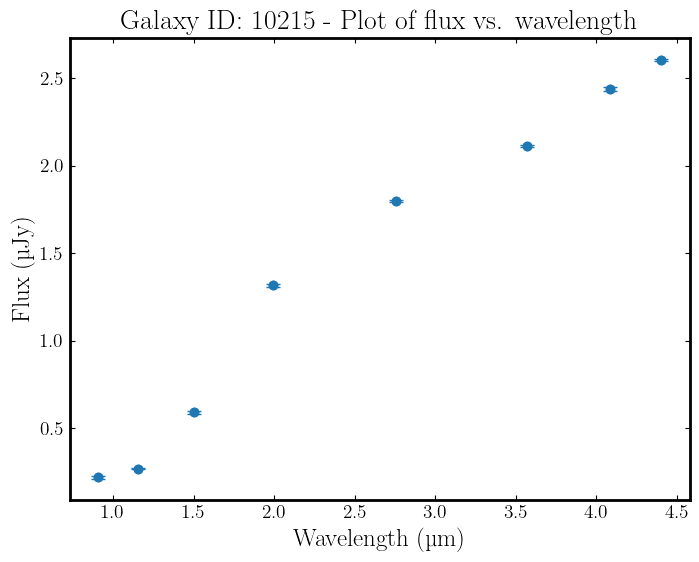

In [1309]:
# Convert from Angstrom to uJy 
pivot_wavelength = np.array(PHOTPLAM) * 1.e-4

# Generate the plot 
fig = plt.figure(figsize=(8, 6))
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.scatter(pivot_wavelength, Flux_back_corr * 1.e-2) 
plt.errorbar(pivot_wavelength, Flux_back_corr * 1.e-2, yerr = Flux_err_back * 1.e-2, fmt="o", capsize = 5)
plt.ylabel(r'Flux (\textmu Jy)', fontsize = 18)
plt.xlabel(r'Wavelength (\textmu m)', fontsize = 18)
plt.title(f'Galaxy ID: {Name} - Plot of flux vs. wavelength', fontsize = 20)
plt.show()

In [1310]:
phot_data = [] 
err_data = []
for i in range(len(Filters) - 0):
    i = i + 0
    phot_added_filter = round(Flux_back_corr[i]/100,7)
    err_added_filter = round(Flux_err_back[i]/100,7)
    phot_data.append(phot_added_filter)
    err_data.append(err_added_filter)

photometry = np.c_[phot_data, err_data]

# 2. Define a loading function
def load_data(ID):
    phot_data = [] 
    err_data = []
    for i in range(len(Filters) - 0):
        i = i + 0
        phot_added_filter = round(Flux_back_corr[i]/100,7)
        err_added_filter = round(Flux_err_back[i]/100,7)
        phot_data.append(phot_added_filter)
        err_data.append(err_added_filter)
    
    photometry = np.c_[phot_data, err_data]

    return photometry 

print(photometry)

[[0.2187735 0.0079221]
 [0.2677192 0.0048347]
 [0.5898275 0.0083659]
 [1.3149489 0.0064705]
 [1.79832   0.0057421]
 [2.1107633 0.0047356]
 [2.4385854 0.0108651]
 [2.606276  0.0066287]]
